In [328]:
import pandas as pd
import numpy as np
import math
import matplotlib.pyplot as plt

In [329]:
V_cell = (0.65e-6/2)**2*math.pi*2.25e-6
# dryM_b =  0.88e-16 #kg
# rho_b = dryM_b/V_b + rho_f
# rho_b

In [330]:
rho_p = 1350 #Density MP
rho_b = 1150 #Vibrio density most abundant bacteria plastisphere 
rho_f = 1025 #water density
rho_d = 1100 #density diatoms

a = 1.0e-5 #largest semiaxis
b = 1.0e-5 #medium semiaxis
c = 1.0e-5 #smallest semiaxis


In [331]:
def tvel(a,b,c, rho_p, rho_f, mu=1.002e-3, e=1.0):
    """
    Estimate terminal sinking velocity (m/s) of a super-ellipsoidal particle.
    
    Parameters
    ----------
    a, b, c : particle dimensions in metres (semiaxis). 
    rho_p   : particle density (kg/m^3)
    rho_f   : fluid density (kg/m^3)
    mu      : dynamic viscosity of fluid (Pa.s); default water at ~20 C
    e       : shape parameter epsilon (1 = ellipsoid, 0.2-1.8 range tested)
    """
    t = 14
    mu = 4.2844e-5 + 1/(0.157*((t + 64.993)**2)-91.296) #kinematic viscosity for Temp of SSC
    g = 9.81 
    fact = 1
    if rho_p <= rho_f:
        fact = -1 #raise ValueError
    a, b, c = sorted((a, b, c), reverse=True)
    
    EI = b / a
    FI = c / b
    fe = e**2*(math.gamma(e/2)**3)/math.gamma(e*3/2)
    d_eq = ((4*a*b*c*fe)/math.pi) ** (1/3)
    # equivalent-volume sphere diameter
    dr = abs(rho_p - rho_f)
    d_star = d_eq * (rho_f * dr * g / mu**2)**(1/3)

    L = math.log10(d_star) #(Eq. 31b)
    C1 = 0.11 * L + 0.17
    C2 = 0.21 * L + 0.17
    C3 = -0.48 * L + 0.56
    C4 = 1.05 * L - 0.38

    # sphere reference and shape correction
    u_star_S = 1/(18/d_star**2 + (2.412/(4*math.sqrt(d_star))))
    u_star = EI**C1 * FI**C2 * (C3*e**2 + C4*e + 1 - C3 - C4) * u_star_S

    u_t = u_star * (dr*mu*g / rho_f**2)**(1/3)

    return fact*u_t, d_eq

# Example: sphere, 10 mm diameter, resin (1200 kg/m3) in water


In [332]:
r, deq = tvel(a, b, c, rho_p, rho_f)
print(f"Clean settling velocity: {round(r, 10)} m/s")
V = (4/3)*math.pi*(deq/2)**3
print(f"Clean Volume: {round(V, 20)} m3")
print(f"Clean mass: {round(V*rho_p, 20)} kg")

Clean settling velocity: 6.03533e-05 m/s
Clean Volume: 4.18879e-15 m3
Clean mass: 5.65486678e-12 kg


## Now what about biofilm?

In [ ]:
N_b = 1
V_bio = V_cell*N_b
rho_tot = (rho_p*V + rho_b*V_bio)/ (V + V_bio)



def thickness(a,b,c,V_bio,e=1.0):
    A = (a+b+c)
    B = (a*c + b*c + a*b)
    fe = e**2*(math.gamma(e/2)**3)/math.gamma(e*3/2)
    C = -3*V_bio/(2*fe)
    p = (3*B-A**2)/3
    q = (2*A**3 - 9*A*B + 27*C)/27
    delta = q**2/4 + p**3/27
    if delta >= 0:
        x = (-q/2 + math.sqrt(delta))**(1/3) + (-q/2 - math.sqrt(delta))**(1/3)
    else:
        # Trigonometric solution
        x = 2*math.sqrt(-p/3) * math.cos(math.acos((-q/2) / math.sqrt(-(p/3)**3))/3)
    return x - A/3

thickness(a,b,c,V_bio)

5.941053281945048e-10

In [334]:
th = [0]
rho_T = [rho_p]
v_sink = []
for n in range(0,1000000,100):
    V_bio = V_cell*n
    th.append(thickness(a,b,c,V_bio))
    rho_T.append((rho_p*V + rho_b*V_bio)/ (V + V_bio))
    vel,deq = tvel(a+th[-1],b+th[-1],c+th[-1], rho_T[-1], rho_f, mu=1.002e-3, e=1.0)
    v_sink.append(vel)

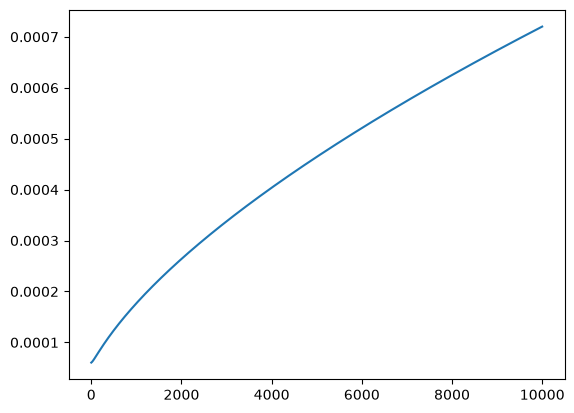

In [335]:
plt.plot(v_sink)